# 02 - Data Cleaning
Goal: produce a clean, validated copy of the data **without changing the raw file** and documenting every decision.

In [1]:
# Import the libraries used in this notebook
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sys.path.append("..")          # lets us import our own src/ package
from src import preprocessing as pp

np.random.seed(42)             # fixed seed for reproducibility
sns.set_theme(style="whitegrid", context="talk")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.max_columns", 50)

## 1. Reload the original dataset

In [2]:
raw = pp.load_raw("../data/raw/ai4i2020.csv")
print("Raw shape:", raw.shape)

Raw shape: (10000, 14)


## 2. Data types and missing values

In [3]:
print(raw.dtypes)
print("\nMissing values per column:\n", pp.check_missing(raw))

UDI                          int64
Product ID                     str
Type                           str
Air temperature [K]        float64
Process temperature [K]    float64
Rotational speed [rpm]       int64
Torque [Nm]                float64
Tool wear [min]              int64
Machine failure              int64
TWF                          int64
HDF                          int64
PWF                          int64
OSF                          int64
RNF                          int64
dtype: object

Missing values per column:
 UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Machine failure            0
TWF                        0
HDF                        0
PWF                        0
OSF                        0
RNF                        0
dtype: int64


## 3. Duplicate rows

In [4]:
print("Exact duplicates:", raw.duplicated().sum())
print("Duplicate UDI:", raw["UDI"].duplicated().sum())

Exact duplicates: 0
Duplicate UDI: 0


## 4. Sensor ranges and physically implausible values

In [5]:
print(raw[pp.SENSOR_COLS].agg(["min", "max"]).T)
pp.check_implausible(raw)

                            min     max
Air temperature [K]       295.3   304.5
Process temperature [K]   305.7   313.8
Rotational speed [rpm]   1168.0  2886.0
Torque [Nm]                 3.8    76.6
Tool wear [min]             0.0   253.0


,column,min_allowed,max_allowed,n_outside
0,Air temperature [K],250,350,0
1,Process temperature [K],250,400,0
2,Rotational speed [rpm],0,10000,0
3,Torque [Nm],0,200,0
4,Tool wear [min],0,1000,0


## 5. Categorical values and inconsistent labels

In [6]:
print("Type values:", raw["Type"].unique())
print("Leading/trailing spaces in Type:", (raw["Type"] != raw["Type"].str.strip()).sum())
print("Product ID prefix == Type:", (raw["Product ID"].str[0] == raw["Type"]).all())

any_mode = raw[pp.FAILURE_MODE_COLS].sum(axis=1) > 0
print("\nFailure=1 but no mode flagged:", ((raw[pp.TARGET_COL] == 1) & ~any_mode).sum())
print("Failure=0 but a mode flagged:", ((raw[pp.TARGET_COL] == 0) & any_mode).sum())
print(raw.loc[(raw[pp.TARGET_COL] == 0) & any_mode, pp.FAILURE_MODE_COLS].sum())

Type values: <ArrowStringArray>
['M', 'L', 'H']
Length: 3, dtype: str
Leading/trailing spaces in Type: 0
Product ID prefix == Type: True

Failure=1 but no mode flagged: 9
Failure=0 but a mode flagged: 18
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64


**Decision:** the label inconsistencies come from the dataset design (e.g. random failures, RNF, are not always reflected in the target).
We **keep `Machine failure` exactly as provided** because it is the official target; changing labels would be guessing.

## 6. Investigate outliers (no automatic deletion)

In [7]:
outliers = pp.iqr_outlier_counts(raw)
outliers

,column,lower_fence,upper_fence,n_outliers,pct
0,Air temperature [K],293.50,306.30,0,0.00
1,Process temperature [K],305.35,314.55,0,0.00
2,Rotational speed [rpm],1139.50,1895.50,418,4.18
3,Torque [Nm],12.80,67.20,69,0.69
4,Tool wear [min],-110.50,325.50,0,0.00


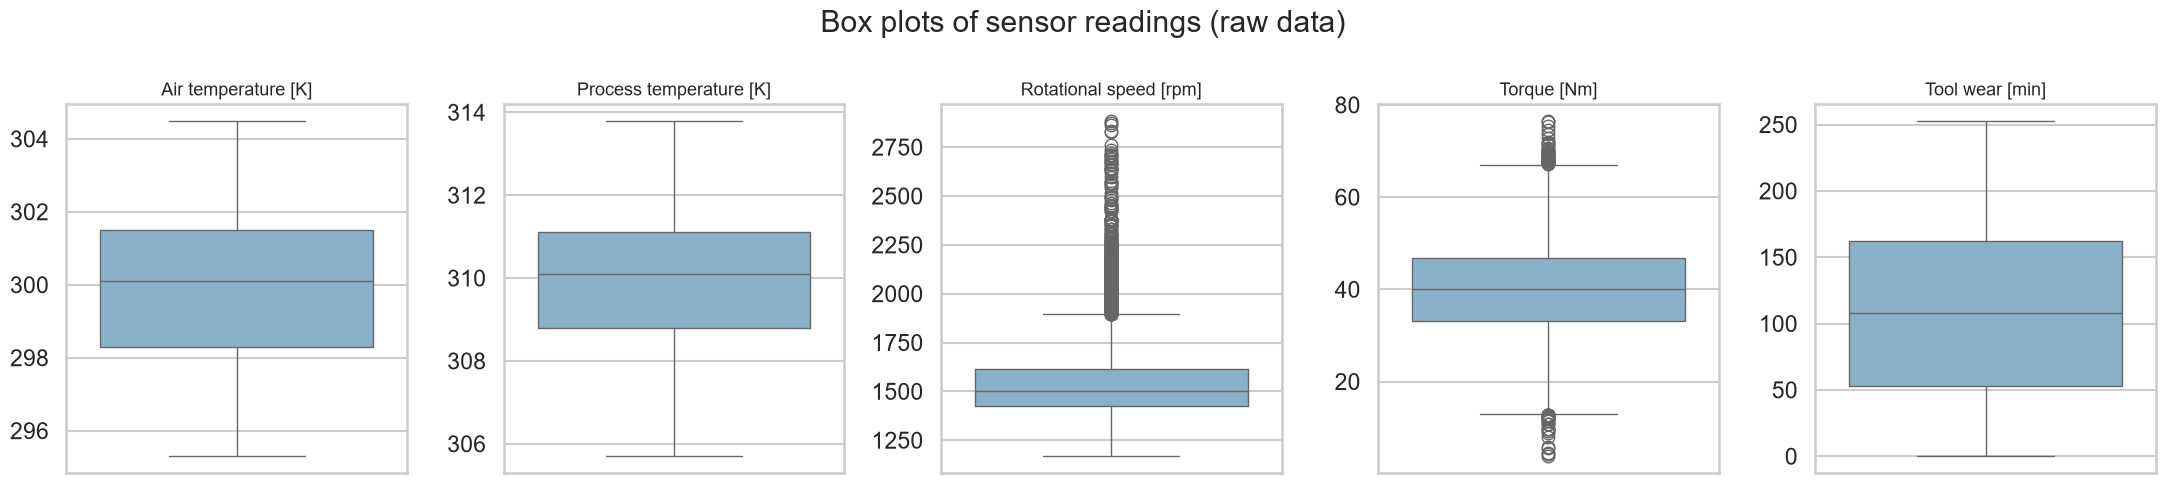

In [8]:
fig, axes = plt.subplots(1, 5, figsize=(22, 5))
for ax, col in zip(axes, pp.SENSOR_COLS):
    sns.boxplot(y=raw[col], ax=ax, color="#7fb3d5")
    ax.set_title(col, fontsize=13)
    ax.set_ylabel("")
plt.suptitle("Box plots of sensor readings (raw data)")
plt.tight_layout(); plt.show()

In [9]:
# Are the IQR outliers linked to failures?
for col in ["Rotational speed [rpm]", "Torque [Nm]"]:
    q1, q3 = raw[col].quantile([.25, .75]); iqr = q3 - q1
    mask = (raw[col] < q1 - 1.5*iqr) | (raw[col] > q3 + 1.5*iqr)
    print(f"{col}: {mask.sum()} outliers | failure rate among outliers = "
          f"{raw.loc[mask, pp.TARGET_COL].mean():.1%} vs overall {raw[pp.TARGET_COL].mean():.1%}")

Rotational speed [rpm]: 418 outliers | failure rate among outliers = 8.4% vs overall 3.4%
Torque [Nm]: 69 outliers | failure rate among outliers = 89.9% vs overall 3.4%


**Interpretation:** IQR outliers appear only in rotational speed and torque. These values are physically possible
(high speed with low torque and vice versa) and the failure rate among them is much higher than average —
they carry exactly the signal we want to study. **They are kept.**

## 7–8. Apply only justified cleaning operations (with log)

In [10]:
clean, log = pp.clean_data(raw)
log_df = pd.DataFrame(log)
log_df["reason"] = [
    "Guard against hidden whitespace in IDs",
    "Guard against hidden whitespace / mixed case in Type",
    "Exact duplicates would double-count observations",
    "Rows with missing values cannot be analysed (none present, so nothing removed)",
    "Readings outside physical limits would be sensor errors (none found)",
    "Type is an ordinal quality grade (L < M < H)",
]
log_df

,step,rows_affected,reason
0,Strip/standardise text in 'Product ID',0,Guard against hidden whitespace in IDs
1,Strip/standardise text in 'Type',0,Guard against hidden whitespace / mixed case i...
2,Drop exact duplicate rows,0,Exact duplicates would double-count observations
3,Drop rows with missing values,0,Rows with missing values cannot be analysed (n...
4,Drop physically implausible readings,0,Readings outside physical limits would be sens...
5,Convert 'Type' to ordered category (L<M<H),0,Type is an ordinal quality grade (L < M < H)


## 9. Compare original and cleaned shapes

In [11]:
print("Original:", raw.shape, "| Cleaned:", clean.shape)
print("Rows removed:", len(raw) - len(clean))
print("Failure rate original vs cleaned:", raw[pp.TARGET_COL].mean(), clean[pp.TARGET_COL].mean())

Original: (10000, 14) | Cleaned: (10000, 14)
Rows removed: 0
Failure rate original vs cleaned: 0.0339 0.0339


## 10. Verify schema and valid values

In [12]:
pp.validate_schema(clean)
print("Schema validation passed ✅")
print(clean.dtypes)

Schema validation passed ✅
UDI                           int64
Product ID                      str
Type                       category
Air temperature [K]         float64
Process temperature [K]     float64
Rotational speed [rpm]        int64
Torque [Nm]                 float64
Tool wear [min]               int64
Machine failure               int64
TWF                           int64
HDF                           int64
PWF                           int64
OSF                           int64
RNF                           int64
dtype: object


## 11. Save cleaned dataset

In [13]:
from pathlib import Path
Path("../data/processed").mkdir(parents=True, exist_ok=True)
clean.to_csv("../data/processed/cleaned_data.csv", index=False)
check = pd.read_csv("../data/processed/cleaned_data.csv")
print("Saved and re-read:", check.shape)

Saved and re-read: (10000, 14)


## 12. Cleaning report

In [14]:
print("CLEANING REPORT")
print("=" * 40)
print(f"Raw rows: {len(raw)}   Cleaned rows: {len(clean)}")
for _, r in log_df.iterrows():
    print(f"- {r['step']}: {r['rows_affected']} rows affected -> {r['reason']}")
print("- Statistical outliers: investigated, KEPT (informative)")
print("- Label inconsistencies: documented, KEPT (official target unchanged)")

CLEANING REPORT
Raw rows: 10000   Cleaned rows: 10000
- Strip/standardise text in 'Product ID': 0 rows affected -> Guard against hidden whitespace in IDs
- Strip/standardise text in 'Type': 0 rows affected -> Guard against hidden whitespace / mixed case in Type
- Drop exact duplicate rows: 0 rows affected -> Exact duplicates would double-count observations
- Drop rows with missing values: 0 rows affected -> Rows with missing values cannot be analysed (none present, so nothing removed)
- Drop physically implausible readings: 0 rows affected -> Readings outside physical limits would be sensor errors (none found)
- Convert 'Type' to ordered category (L<M<H): 0 rows affected -> Type is an ordinal quality grade (L < M < H)
- Statistical outliers: investigated, KEPT (informative)
- Label inconsistencies: documented, KEPT (official target unchanged)


**Summary:** the AI4I data is already very clean. No rows were removed; the only change is converting `Type` to an ordered category.
The raw file in `data/raw/` is unchanged.